# Task 4 — Network Utilization

## Analytical Question

**How heavily was Ethereum's blockspace being utilized during the 30-day period?**

Analyze the metrics supported by the BigQuery dataset:

- Average transactions per block
- Total gas used
- Average gas used per block
- Average gas limit
- Gas utilization

Gas utilization is calculated as:

**Gas utilization = Gas used / Gas limit × 100**

### Workflow

**BigQuery → GoogleSQL → Analytical Dataset → Pandas → Analysis → Visualization → Insight**


### Data source

Google Cloud BigQuery Ethereum Mainnet Blockchain Analytics dataset:
- **Source dataset:** `bigquery-public-data.goog_blockchain_ethereum_mainnet_us`
- **Source table:** `blocks`
- **SQL query:** `sql/04_network_utilization.sql`

Relevant fields:

- `block_timestamp`
- `transaction_count`
- `gas_used`
- `gas_limit`

The blocks table already provides `transaction_count`, so no transaction-table join is required for these network-utilization metrics.

### Analysis window

- Start: **2026-08-24 10:01:35 UTC**
- End: **2026-09-23 10:01:35 UTC**
- Duration: **30 days**
- Start block: **25,824,304**
- End block: **26,039,452**

The first and last calendar dates are partial days because the window starts and ends at 10:01:35 UTC.

In [58]:
import pandas as pd
import matplotlib.pyplot as plt

import pandas.io.formats.format as pf
# Force Pandas' internal integer formatter to use commas seperator globally
class CommaIntFormatter(pf._GenericArrayFormatter):
    def _format_strings(self):
        formatter = self.formatter or '{:,d}'.format
        return [formatter(x) for x in self.values]

# Override the default engine
pf._IntArrayFormatter = CommaIntFormatter

# Format float with comma(removes E-notation)
pd.set_option('display.float_format', lambda x: f' {x:,.2f}')

## Load the Analytical Dataset


In [59]:
import pandas as pd

df = pd.read_csv(
    "../data/processed/daily_network_utilization.csv"
)

df["date"] = pd.to_datetime(df["date"])

df.head()


,date,avg_transactions_per_block,total_gas_used,avg_gas_used_per_block,avg_gas_limit,avg_gas_utilization_pct
0,2026-08-24,276.85,"126,843,024,122","30,345,221.08","59,996,618.39",50.58
1,2026-08-25,278.05,"218,050,922,535","30,394,608.66","59,996,697.13",50.66
2,2026-08-26,264.68,"217,769,296,656","30,363,817.16","59,996,377.27",50.61
3,2026-08-27,269.08,"218,437,823,137","30,423,095.14","59,996,438.66",50.71
4,2026-08-28,265.33,"218,212,568,813","30,425,623.09","59,996,744.99",50.71


## Validate the Dataset

Check:

- row count;
- columns;
- data types;
- missing values;
- duplicate dates.


In [60]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate dates:", df["date"].duplicated().sum())


Shape: (31, 6)

Columns:
Index(['date', 'avg_transactions_per_block', 'total_gas_used',
       'avg_gas_used_per_block', 'avg_gas_limit', 'avg_gas_utilization_pct'],
      dtype='object')

Data types:
date                          datetime64[ns]
avg_transactions_per_block           float64
total_gas_used                         int64
avg_gas_used_per_block               float64
avg_gas_limit                        float64
avg_gas_utilization_pct              float64
dtype: object

Missing values:
date                         0
avg_transactions_per_block   0
total_gas_used               0
avg_gas_used_per_block       0
avg_gas_limit                0
avg_gas_utilization_pct      0
dtype: int64

Duplicate dates: 0


## Handle Partial Days

The 30-day analysis window produces two partial calendar days: the starting date and ending date. For comparable daily analysis, exclude these two partial days.

In [61]:
# The two partial days
first_day = df["date"].min()
last_day = df["date"].max()

# keep only complete days
complete_days = df[(df["date"] > first_day) & (df["date"] < last_day)]
complete_days.shape

(29, 6)

In [62]:
# .copy() creates an independent DataFrame that we can safely modify.
complete_days = df[(df["date"] > first_day) & (df["date"] < last_day)].copy()

## Transactions per Block

Analyze the average number of transactions included in each block.


In [63]:
mean_tx_per_block = complete_days["avg_transactions_per_block"].mean()
median_tx_per_block = complete_days["avg_transactions_per_block"].median()

mean_tx_per_block, median_tx_per_block


(np.float64(265.1821001295699), np.float64(267.39882861525604))

In [64]:
highest_tx_block_day = complete_days.loc[
    complete_days["avg_transactions_per_block"].idxmax()
]

lowest_tx_block_day = complete_days.loc[
    complete_days["avg_transactions_per_block"].idxmin()
]

highest_tx_block_day, lowest_tx_block_day


(date                          2026-09-22 00:00:00
 avg_transactions_per_block                 292.96
 total_gas_used                       216553109908
 avg_gas_used_per_block              30,295,622.54
 avg_gas_limit                       59,996,036.96
 avg_gas_utilization_pct                     50.50
 Name: 29, dtype: object,
 date                          2026-09-13 00:00:00
 avg_transactions_per_block                 205.57
 total_gas_used                       218215505326
 avg_gas_used_per_block              30,387,899.36
 avg_gas_limit                       59,995,989.84
 avg_gas_utilization_pct                     50.65
 Name: 20, dtype: object)

## Gas Utilization

Analyze how much of the available block gas limit was used on average each day.


In [65]:
mean_gas_utilization = complete_days["avg_gas_utilization_pct"].mean()
median_gas_utilization = complete_days["avg_gas_utilization_pct"].median()

mean_gas_utilization, median_gas_utilization


(np.float64(50.61075839592423), np.float64(50.61141443164324))

In [66]:
highest_gas_utilization_day = complete_days.loc[
    complete_days["avg_gas_utilization_pct"].idxmax()
]

lowest_gas_utilization_day = complete_days.loc[
    complete_days["avg_gas_utilization_pct"].idxmin()
]

highest_gas_utilization_day, lowest_gas_utilization_day


(date                          2026-08-30 00:00:00
 avg_transactions_per_block                 250.04
 total_gas_used                       218834441007
 avg_gas_used_per_block              30,491,074.41
 avg_gas_limit                       59,996,518.54
 avg_gas_utilization_pct                     50.82
 Name: 6, dtype: object,
 date                          2026-09-19 00:00:00
 avg_transactions_per_block                 243.71
 total_gas_used                       216828371906
 avg_gas_used_per_block              30,274,835.51
 avg_gas_limit                       59,996,478.37
 avg_gas_utilization_pct                     50.46
 Name: 26, dtype: object)

## Gas Usage

Examine daily gas consumption and average gas used per block.


In [67]:
mean_total_gas = complete_days["total_gas_used"].mean()
median_total_gas = complete_days["total_gas_used"].median()

mean_avg_gas_used = complete_days["avg_gas_used_per_block"].mean()
median_avg_gas_used = complete_days["avg_gas_used_per_block"].median()

mean_total_gas, median_total_gas, mean_avg_gas_used, median_avg_gas_used


(np.float64(217766324884.72415),
 np.float64(217854521065.0),
 np.float64(30364544.014123823),
 np.float64(30364888.517212607))

## 7-Day Rolling Averages

Use rolling averages to identify broader movement in blockspace utilization.


In [68]:
complete_days["tx_per_block_rolling_7d"] = (
    complete_days["avg_transactions_per_block"]
    .rolling(7)
    .mean()
)

complete_days["gas_utilization_rolling_7d"] = (
    complete_days["avg_gas_utilization_pct"]
    .rolling(7)
    .mean()
)

complete_days[
    [
        "date",
        "avg_transactions_per_block",
        "tx_per_block_rolling_7d",
        "avg_gas_utilization_pct",
        "gas_utilization_rolling_7d"
    ]
].tail(10)


,date,avg_transactions_per_block,tx_per_block_rolling_7d,avg_gas_utilization_pct,gas_utilization_rolling_7d
20,2026-09-13,205.57,258.56,50.65,50.61
21,2026-09-14,266.09,257.96,50.67,50.62
22,2026-09-15,264.22,258.14,50.54,50.61
23,2026-09-16,272.71,258.90,50.55,50.61
24,2026-09-17,272.79,256.10,50.47,50.58
25,2026-09-18,285.06,255.06,50.54,50.57
26,2026-09-19,243.71,258.59,50.46,50.56
27,2026-09-20,236.49,263.01,50.53,50.54
28,2026-09-21,291.80,266.68,50.52,50.52
29,2026-09-22,292.96,270.79,50.50,50.51


## Visualization — Transactions per Block


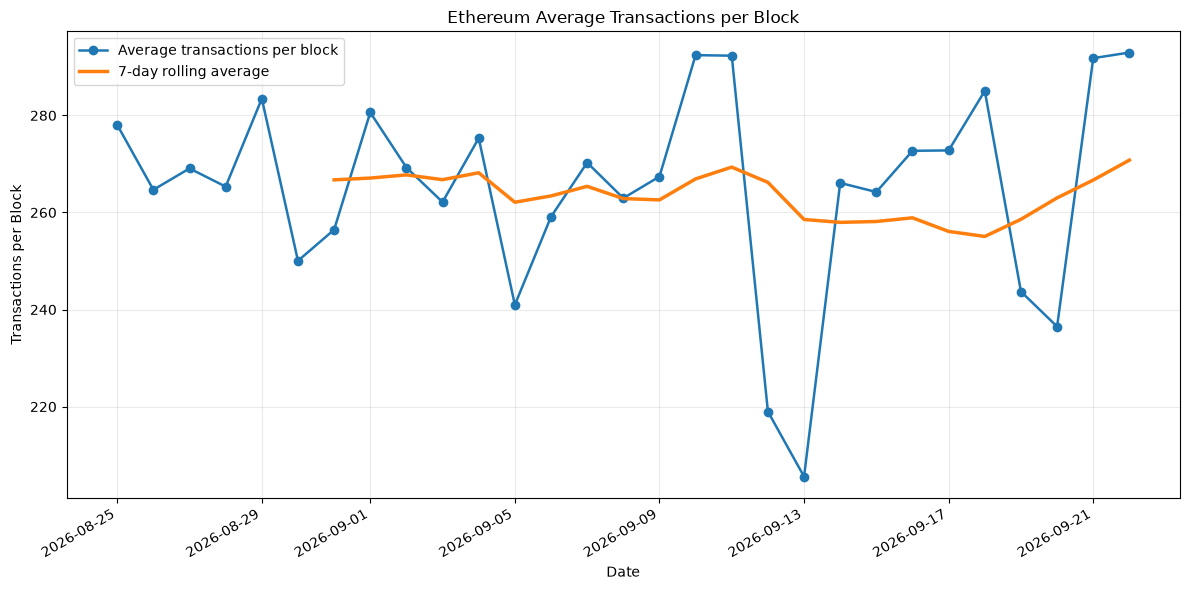

In [69]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    complete_days["date"],
    complete_days["avg_transactions_per_block"],
    marker="o",
    linewidth=1.8,
    label="Average transactions per block"
)

ax.plot(
    complete_days["date"],
    complete_days["tx_per_block_rolling_7d"],
    linewidth=2.5,
    label="7-day rolling average"
)

ax.set_title("Ethereum Average Transactions per Block")
ax.set_xlabel("Date")
ax.set_ylabel("Transactions per Block")
ax.legend()
ax.grid(alpha=0.25)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


## Plotly Visualization — Transactions per Block


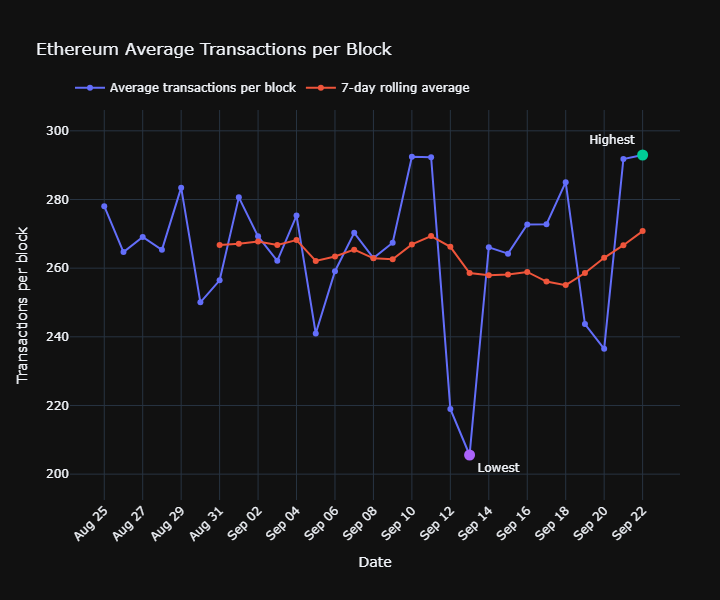

In [76]:
import plotly.express as px

# Prepare data for visualization
plot_df = complete_days[
    ["date", "avg_transactions_per_block", "tx_per_block_rolling_7d"]
].copy()

plot_df = plot_df.rename(
    columns={
        "avg_transactions_per_block": "Average transactions per block",
        "tx_per_block_rolling_7d": "7-day rolling average"
    }
)

plot_df = plot_df.melt(
    id_vars="date",
    var_name="metric",
    value_name="transactions_per_block"
)


# Identify highest and lowest activity days
highest_day = complete_days.loc[
    complete_days["avg_transactions_per_block"].idxmax()
]

lowest_day = complete_days.loc[
    complete_days["avg_transactions_per_block"].idxmin()
]


# Create the line chart
fig = px.line(
    plot_df,
    x="date",
    y="transactions_per_block",
    color="metric",
    title="Ethereum Average Transactions per Block",
    markers=True,
    labels={
        "date": "Date",
        "transactions_per_block": "Transactions per block",
        "metric": ""
    }
)


# Chart layout
fig.update_layout(
    template="plotly_dark",
    hovermode="x unified",
    height=600,

    margin=dict(
        l=70,
        r=40,
        t=110,
        b=100
    ),

    xaxis=dict(
        title="Date",
        hoverformat="%b %d, %Y",
        tickmode="auto",
        nticks=20,
        tickformat="%b %d",
        tickangle=-45
    ),

    yaxis=dict(
        title="Transactions per block",
        fixedrange=True
    ),

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    )
)


# Format markers and hover information
fig.update_traces(
    marker=dict(size=6),
    hovertemplate=(
        "<b>%{fullData.name}</b>: "
        "%{y:,.2f} transactions/block"
        "<extra></extra>"
    )
)


# Add highest-activity marker
fig.add_scatter(
    x=[highest_day["date"]],
    y=[highest_day["avg_transactions_per_block"]],
    mode="markers+text",
    text=["Highest"],
    textposition="top left",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Highest activity</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:,.2f} transactions/block"
        "<extra></extra>"
    )
)


# Add lowest-activity marker
fig.add_scatter(
    x=[lowest_day["date"]],
    y=[lowest_day["avg_transactions_per_block"]],
    mode="markers+text",
    text=["Lowest"],
    textposition="bottom right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Lowest activity</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:,.2f} transactions/block"
        "<extra></extra>"
    )
)


# Add padding to prevent annotations from being clipped
y_min = complete_days["avg_transactions_per_block"].min()
y_max = complete_days["avg_transactions_per_block"].max()

padding = (y_max - y_min) * 0.15

fig.update_yaxes(
    range=[
        y_min - padding,
        y_max + padding
    ]
)


# Display chart
fig.show()

## Visualization — Gas Utilization


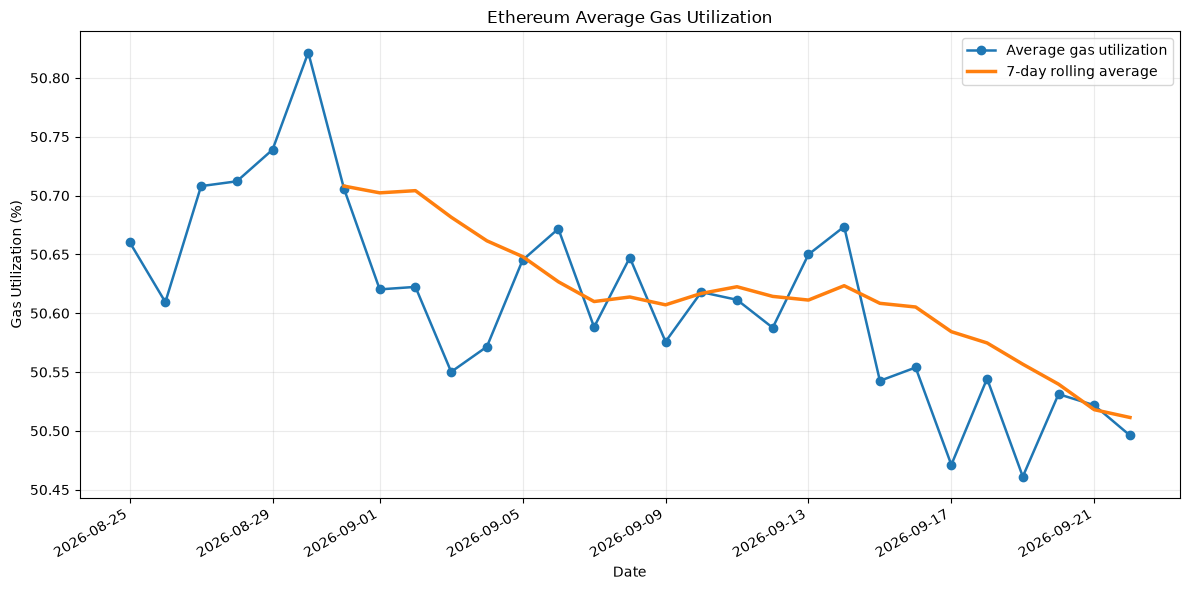

In [70]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    complete_days["date"],
    complete_days["avg_gas_utilization_pct"],
    marker="o",
    linewidth=1.8,
    label="Average gas utilization"
)

ax.plot(
    complete_days["date"],
    complete_days["gas_utilization_rolling_7d"],
    linewidth=2.5,
    label="7-day rolling average"
)

ax.set_title("Ethereum Average Gas Utilization")
ax.set_xlabel("Date")
ax.set_ylabel("Gas Utilization (%)")
ax.legend()
ax.grid(alpha=0.25)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


## Plotly Visualization — Gas Utilization


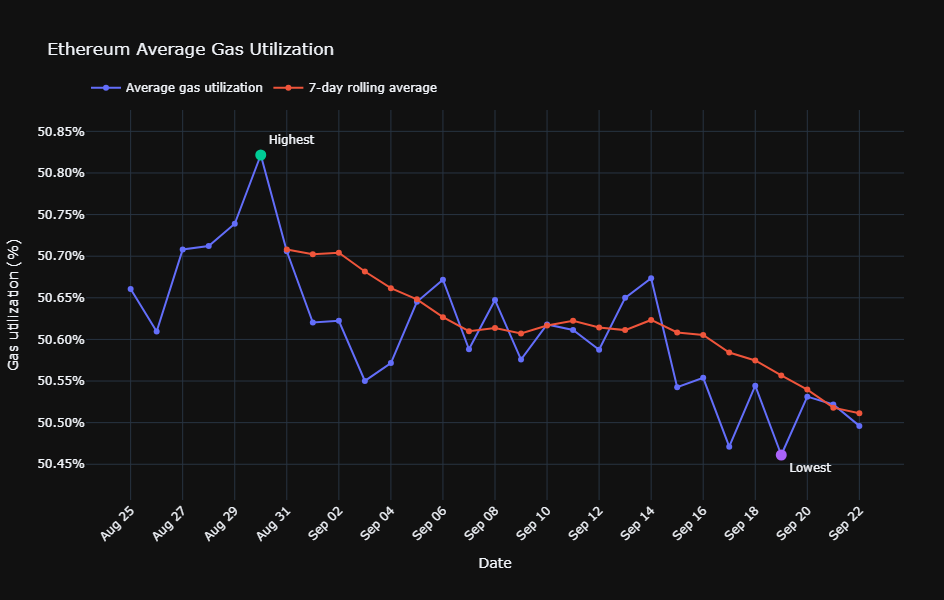

In [77]:
# Prepare data for visualization
plot_df = complete_days[
    ["date", "avg_gas_utilization_pct", "gas_utilization_rolling_7d"]
].copy()

plot_df = plot_df.rename(
    columns={
        "avg_gas_utilization_pct": "Average gas utilization",
        "gas_utilization_rolling_7d": "7-day rolling average"
    }
)

plot_df = plot_df.melt(
    id_vars="date",
    var_name="metric",
    value_name="gas_utilization_pct"
)


# Identify highest and lowest utilization days
highest_day = complete_days.loc[
    complete_days["avg_gas_utilization_pct"].idxmax()
]

lowest_day = complete_days.loc[
    complete_days["avg_gas_utilization_pct"].idxmin()
]


# Create the line chart
fig = px.line(
    plot_df,
    x="date",
    y="gas_utilization_pct",
    color="metric",
    title="Ethereum Average Gas Utilization",
    markers=True,
    labels={
        "date": "Date",
        "gas_utilization_pct": "Gas utilization (%)",
        "metric": ""
    }
)


# Chart layout
fig.update_layout(
    template="plotly_dark",
    hovermode="x unified",
    height=600,

    margin=dict(
        l=70,
        r=40,
        t=110,
        b=100
    ),

    xaxis=dict(
        title="Date",
        hoverformat="%b %d, %Y",
        tickmode="auto",
        nticks=20,
        tickformat="%b %d",
        tickangle=-45
    ),

    yaxis=dict(
        title="Gas utilization (%)",
        ticksuffix="%",
        tickformat=".2f",
        fixedrange=True
    ),

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    )
)


# Format markers and hover information
fig.update_traces(
    marker=dict(size=6),
    hovertemplate=(
        "<b>%{fullData.name}</b>: "
        "%{y:.2f}%"
        "<extra></extra>"
    )
)


# Add highest-utilization marker
fig.add_scatter(
    x=[highest_day["date"]],
    y=[highest_day["avg_gas_utilization_pct"]],
    mode="markers+text",
    text=["Highest"],
    textposition="top right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Highest utilization</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:.2f}%"
        "<extra></extra>"
    )
)


# Add lowest-utilization marker
fig.add_scatter(
    x=[lowest_day["date"]],
    y=[lowest_day["avg_gas_utilization_pct"]],
    mode="markers+text",
    text=["Lowest"],
    textposition="bottom right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Lowest utilization</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:.2f}%"
        "<extra></extra>"
    )
)


# Add padding to prevent annotations from being clipped
y_min = complete_days["avg_gas_utilization_pct"].min()
y_max = complete_days["avg_gas_utilization_pct"].max()

padding = (y_max - y_min) * 0.15

fig.update_yaxes(
    range=[
        y_min - padding,
        y_max + padding
    ]
)


# Display chart
fig.show()

## Variability

Measure the variability of transactions per block and gas utilization.


In [71]:
tx_per_block_std = complete_days["avg_transactions_per_block"].std()
tx_per_block_cv = (
    tx_per_block_std / mean_tx_per_block * 100
)

gas_utilization_std = complete_days["avg_gas_utilization_pct"].std()
gas_utilization_cv = (
    gas_utilization_std / mean_gas_utilization * 100
)

tx_per_block_std, tx_per_block_cv, gas_utilization_std, gas_utilization_cv


(np.float64(20.948725385889997),
 np.float64(7.899750916692453),
 np.float64(0.08306218163558322),
 np.float64(0.1641196146198678))

## Finding | Evidence | Meaning

### Finding

Ethereum's **gas utilization was highly stable** across the 29 complete days, while the number of transactions included per block showed substantially more day-to-day variation.

### Evidence

- **Mean transactions per block:** 265.18
- **Median transactions per block:** 267.40
- **Highest:** September 22 — **292.96 transactions/block**
- **Lowest:** September 13 — **205.57 transactions/block**
- **Mean gas utilization:** **50.61%**
- **Median gas utilization:** **50.61%**
- **Highest gas-utilization day:** August 30 — **50.82%**
- **Lowest gas-utilization day:** September 19 — **50.46%**
- **Mean daily gas used:** approximately **217.77 billion gas**
- **Median daily gas used:** approximately **217.85 billion gas**
- **Transactions per block CV:** **7.90%**
- **Gas-utilization CV:** **0.16%**

The 7-day rolling average for gas utilization remained close to 50.5–50.6%, while the rolling average for transactions per block moved more noticeably.

### Meaning

The data shows that **Ethereum's average block gas capacity was used at roughly half of the available limit throughout the period**, with very little variation in gas utilization. In contrast, the number of transactions included per block varied more substantially.

This means that changes in transactions per block did not correspond to large changes in the percentage of block gas capacity used during this period. The results describe observed blockspace utilization; they do not by themselves establish why transaction counts or gas usage changed.


## Limitations

- The analysis covers only a **30-day period**, so the observed gas-utilization and transaction-per-block patterns do not establish longer-term network-utilization trends.

- **Gas utilization measures gas consumed relative to the block gas limit.** It does not directly measure the number of transactions a block can accommodate, since transactions can require different amounts of gas depending on their execution complexity.

- The analysis uses **daily averages across blocks**, so individual blocks with unusually high or low gas usage may not be visible in the daily-level results.

- The **first and last calendar dates are partial days** because the analysis window does not align exactly with calendar-day boundaries. These dates were excluded from the comparable daily analysis.

- The analysis identifies **patterns in blockspace utilization but does not establish their causes**. Additional transaction-level or application-level analysis would be required to explain why gas usage or transactions per block changed on particular days.